In [1]:
# import all python add-ons etc that will be needed later on
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from sympy import *
from scipy.integrate import quad,odeint
init_printing()                      # allows printing of SymPy results in typeset maths format
plt.rcParams.update({'font.size': 16})  # set font size for plots

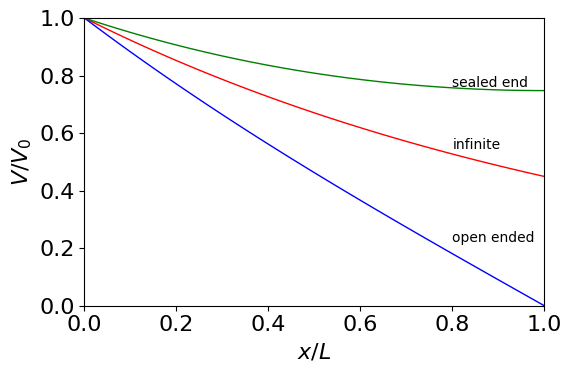

In [2]:
#  Cable equation  x == u in text diffeqns 11.2

fig1= plt.figure( figsize=(6, 4) )
plt.rcParams.update({'font.size': 16})  # set font size for plots
L = 1.0
V0 = 1

lam = 1.25
f01=lambda x:V0*np.exp(-x/lam)

f02=lambda x: V0*(np.exp((L-x)/lam)-np.exp(-(L-x)/lam))/(np.exp(L/lam)-np.exp(-L/lam))

f03=lambda x: V0*(np.exp((L-x)/lam)+np.exp(-(L-x)/lam) )/(np.exp(L/lam)+np.exp(-L/lam))

x = np.linspace(0,L,100)

plt.plot(x/L,f01(x),color='red',linewidth=1)
plt.plot(x/L,f02(x),color='blue',linewidth=1)
plt.plot(x/L,f03(x),color='green',linewidth=1)

plt.text(0.80,f01(x[75]),'infinite',fontsize=10)
plt.text(0.80,f02(x[75]),'open ended',fontsize=10)
plt.text(0.80,f03(x[75]),'sealed end',fontsize=10)

plt.ylim([0,1])
plt.xlim([0,1])
plt.ylabel(r'$V/V_0$')
plt.xlabel(r'$x/L$')
#plt.xticks([0,0.5,1,1.5])

plt.tight_layout()

#plt.savefig('diffeqn-fig11d.png')
plt.show()

In [3]:
2*np.exp(-L)

8.0


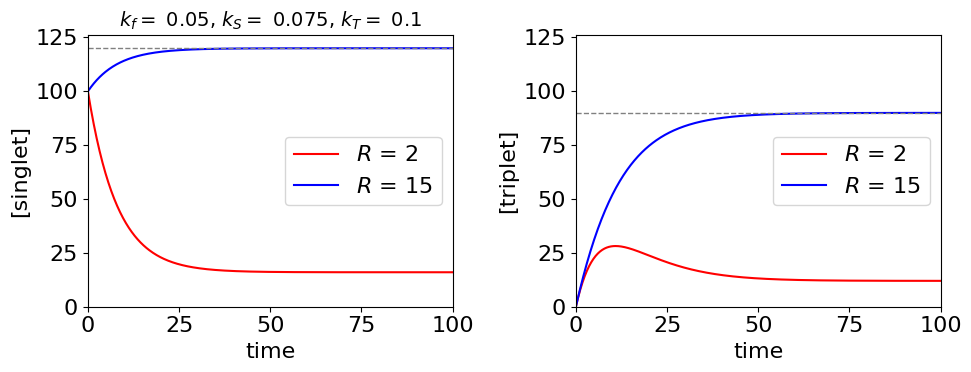

In [4]:
# Q22
fig1= plt.figure( figsize=(10, 4) )
plt.rcParams.update({'font.size': 16})  # set font size for plots
ax0 = fig1.add_subplot(1,2,1)
ax1 = fig1.add_subplot(1,2,2)

S = lambda t, R, S0 : R*tau - (R*tau - S0)*np.exp(-t/tau)
 
kf  = 0.05
kS  = 0.075
tau = 1.0/(kf + kS)
kT  = 0.1
maxt= 100
t=np.linspace(0,maxt,500)  
S0  = 100
R=2
ax0.plot(t, S(t,R,S0),color='red',label=r'$R$ = '+str(R))
R=15
ax0.plot(t, S(t,R,S0),color='blue',label=r'$R$ = '+str(R))
ax0.set_xlabel('time')
ax0.set_ylabel('[singlet]')
ax0.set_ylim([0,R*tau*1.05])
ax0.set_xlim([0,100])

ax0.axhline(R*tau,color='grey',linewidth=1,linestyle='dashed')
ax0.legend()

# triplet
print(tau)
Triplet= lambda t, R , S0 : kS *(R*tau)/(kT) - kS*(R*tau-S0)/(kT-kf-kS) * np.exp(-t/tau) \
                           -kS*((R*tau)/(kT) -    (R*tau-S0)/(kT-kf-kS) )* np.exp(-kT*t)
R = 2
ax1.plot(t, Triplet(t,R,S0),color='red',label=r'$R$ = '+str(R))
R = 15
ax1.plot(t, Triplet(t,R,S0),color='blue',label=r'$R$ = '+str(R))
ax1.legend()
ax1.set_xlim([0,maxt])
mx = max([R*kS/((kf+kS)*kT),R*tau])
ax1.set_ylim([0,1.05*mx])
ax0.set_ylim([0,1.05*mx])
ax1.axhline(R*kS/((kf+kS)*kT),color='grey',linewidth=1,linestyle='dashed')
ax1.set_xlabel('time')
ax1.set_ylabel('[triplet]')

ax0.set_title(r'$k_f =$ '+str(kf)+r', $k_S =$ '+str(kS)+r', $k_T =$ '+str(kT),fontsize=14)

ax0.set_yticks([0,25,50,75,100,125])
ax0.set_yticks([0,25,50,75,100,125])
ax0.set_xticks([0,25,50,75,100])
ax1.set_xticks([0,25,50,75,100])
plt.tight_layout()

#plt.savefig('diffeqn-fig38a.png')
plt.show()
    

# Q23 

$$\displaystyle A=\frac{k_aI_0}{k_S-k_a}\left(e^{-k_at}-e^{-k_St}  \right) +A_0e^{-k_St}$$



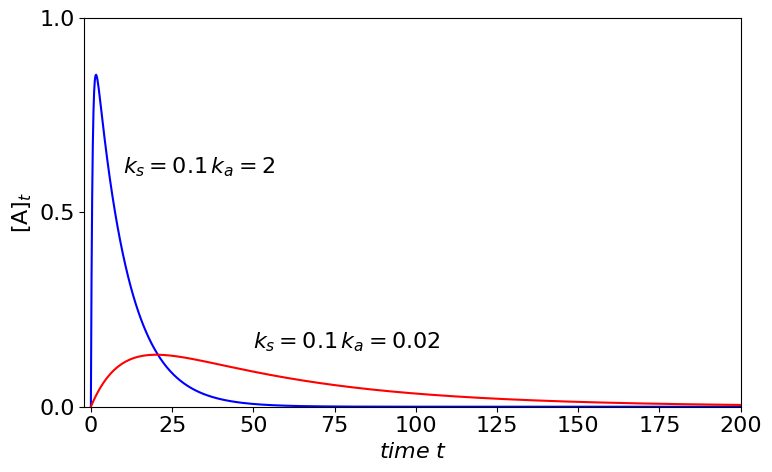

In [5]:
fig1a= plt.figure( figsize=(8, 5) )
plt.rcParams.update({'font.size': 16})  # set font size for plots

I0=1
A0 = 0
ks = 0.1
ka = 2

A=lambda ka,ks,t: (ka*I0)/(ks-ka)*(np.exp(-ka*t)-np.exp(-ks*t))+A0*np.exp(-ks*t)


t=np.linspace(0,200,1000)


plt.plot(t,A(ka,ks,t),color='blue')

plt.plot(t,A(ka/100,ks,t),color='red')
plt.xlim([-2,200])
plt.ylim([0,1])
plt.text(10,0.6, r'$k_s=0.1\,k_a=2$')
plt.text(50,0.15, r'$k_s=0.1\,k_a=0.02$')
plt.xlabel(r'$time\; t$')
plt.ylabel(r'$\mathrm{[A]}_t$')
plt.yticks([0,0.5,1])

plt.tight_layout()
#plt.savefig('diffeqn-fig38b.png')
plt.show()

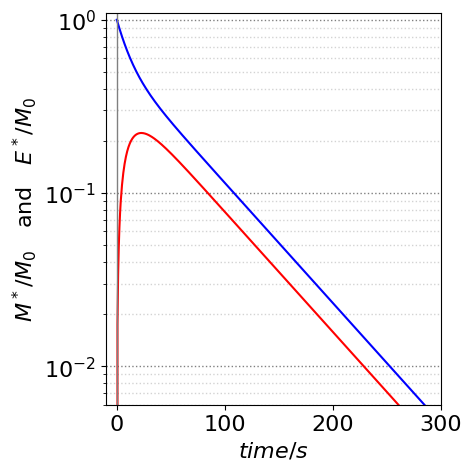

In [6]:
# excimers

fig, ax = plt.subplots(figsize=(5,5))


M0=3e-3  # from question
kf=0.02
ke=0.01
k1=0.05
k2=M0*1e10*1e-9

b = kf + ke + k1 + k2

c = 2*np.sqrt(ke*kf + ke*k2 + k1*kf )

Mstar = lambda t, b, c :0.5*(1+(b-2*(kf+k2))/np.sqrt(b**2-c**2))*np.exp(-(b-np.sqrt(b**2-c**2))*t/2.0) \
                       +0.5*(1-(b-2*(kf+k2))/np.sqrt(b**2-c**2))*np.exp(-(b+np.sqrt(b**2-c**2))*t/2.0)
    
Estar= lambda t, b, c  :k2/(np.sqrt(b**2-c**2))*(np.exp(-(b-np.sqrt(b**2 - c**2))*t/2.0) \
                                                -np.exp(-(b+np.sqrt(b**2 - c**2))*t/2.0))


tmax=300   
t=np.linspace(0,tmax,500)

ax.plot(t,Mstar(t,b,c),color='blue')
ax.plot(t,Estar(t,b,c),color='red')
plt.yscale('log')
plt.ylim([0.006,1.1])
plt.xlim([-10,tmax])
plt.ylabel(r'$M^*/M_0 \quad \mathrm{ and }\quad E^*/M_0$')
plt.xlabel(r'$time /s$')
#ax.yaxis.grid('on')
ax.yaxis.grid(which="major", color='grey', linestyle='dotted', linewidth=1)
ax.yaxis.grid(which="minor", color='lightgrey', linestyle='dotted', linewidth=1)
ax.axvline(0,color='grey',linewidth=1)
plt.tight_layout()
#plt.savefig('diffeqn-fig39.png')
plt.show()

40403994843484.45 172.08001187551147 4.040782823957967e+22 2.5e-11 6.387871584754891e-21 0.043927530111162835 -1.9974874371859296e-11


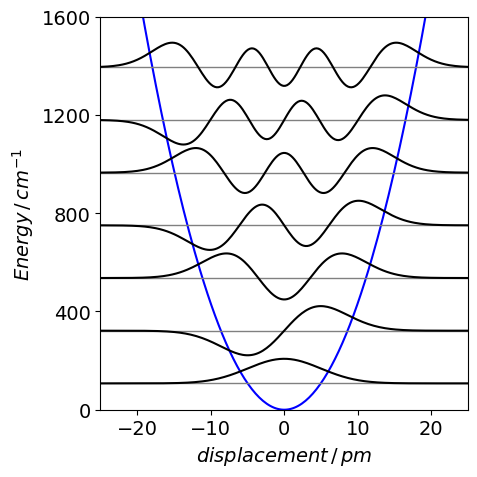

In [7]:
def herm(x,n):
    if n==0:
        return 1
    elif n==1:
        return 2*x
    else:
        return 2*x*herm(x,n-1)-2*(n-1)*herm(x,n-2)
    pass
#------------

hbar= 1.054e-34  # Js
amu = 1.66e-27   # kg
c   = 2.9979e10  # cm/s
m   = 127        # g/mole
jcm = 5.034e22

omega  = 214.5 *2*np.pi*c     # cm^(-1) to 1/s
m1  = m
m2  = m
mu  = m1*m2/(m1+m2)*amu   # in kg
k = mu*(omega)**2  #cm^(-2) cm^2/s^2 kg  =kg/s^2 =N/m

b = mu*omega/hbar
V = lambda x,k : 0.5*k*x**2
#print(mu,k)

E   =  lambda n: hbar*omega*(n+0.5)  # in joules
psi = lambda x,n: np.exp(-b*x**2/2.0)*herm(np.sqrt(b)*x ,n)
pm  = 1e-12
x0  = 25*pm
numx = 200
x   = np.linspace( -x0, x0, numx )  # in metres

print(omega, k, b, x0, E(1), psi(x[50],0),x[20] )


figh= plt.figure( figsize=(5, 5) )
plt.rcParams.update({'font.size': 14})  # set font size for plots

plt.plot(x/pm,V(x,k)*jcm,color='blue')  # plot in cm^{-1}
for n in range(7):
    mx = max( psi(x,n) )
    plt.axhline( E(n)*jcm,linewidth = 1, color='gray')
    plt.plot(x/pm, E(n)*jcm + psi(x,n)/mx*100,color='black')
    pass

plt.ylim([0,3e-20*jcm])
plt.xlim([-x0/pm,x0/pm])
plt.yticks([0,400,800,1200,1600])
plt.ylabel(r'$Energy \,/\, cm^{-1}$')
plt.xlabel(r'$displacement\, /\,pm$')
plt.tight_layout()
#plt.savefig('diffeqn-fig19a.png')

plt.show()
    

321.5654555765612


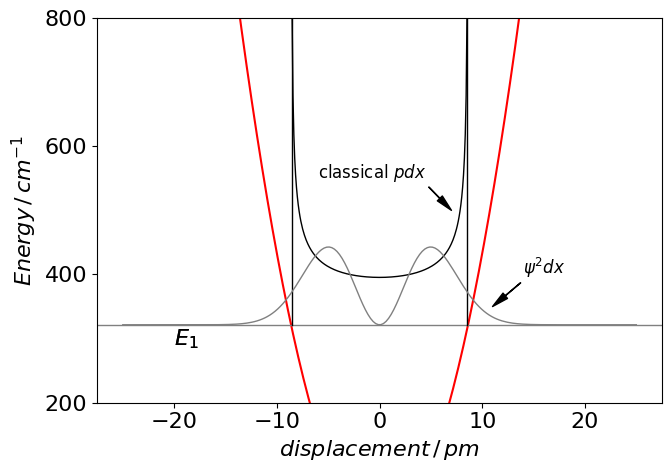

In [8]:
figj= plt.figure( figsize=(7, 5) )
plt.rcParams.update({'font.size': 16})  # set font size for plots

n=1
print(E(n)*jcm)  # wavenumber

xE = lambda n: np.sqrt( 2*E(n)/k )     # unit energy = force * distance  J*m/(N) = kg*m^2s^{-2}/(kg*m/s^{-2}m)=m


#f01 = lambda n,x :1/( np.pi*np.sqrt( (xE(n)**2 - x**2) ) )

def f01(n):
    x = np.linspace(-xE(n)+1e-13,xE(n)-1e-13,200)
    return x,1/( np.pi*np.sqrt( (xE(n)**2 - x**2) ) )

xx,prob=f01(n)
m=len(xx)-1
plt.plot(xx/pm,prob/5e8 + E(n)*jcm,color='black',linewidth=1)

plt.plot(x/pm, V(x,k)*jcm,color='red')
plt.axhline(E(n)*jcm,color='grey',linewidth=1)

#plt.axvline(xE(n)/pm)
#plt.axvline(-xE(n)/pm)
mx = max( psi(x,n) )
plt.plot([ xx[0]/pm, xx[0]/pm ], [  E(n)*jcm, prob[0] + E(n)*jcm],color='black',linewidth=1)
plt.plot([ xx[m]/pm, xx[m]/pm ], [  E(n)*jcm, prob[m] + E(n)*jcm],color='black',linewidth=1)

plt.plot(x/pm, E(n)*jcm + psi(x,n)**2/mx*100,color='grey',linewidth=1)
plt.yticks([200,400,600,800])
plt.ylim([200,800])
plt.ylabel(r'$Energy \,/\, cm^{-1}$')
plt.xlabel(r'$displacement\, /\,pm$')
plt.text(-20,0.90*E(n)*jcm,r'$E_1$')
plt.text(-20,0.90*E(n)*jcm,r'$E_1$')
plt.annotate('classical '+r'$ pdx$', xy=(7, 500), xytext=(-6, 550),
            arrowprops=dict(facecolor='black',width=0.2,headwidth=5),fontsize=12)
plt.annotate(r'$\psi^2dx$', xy=(11, 350), xytext=(14, 400),
            arrowprops=dict(facecolor='black',width=0.2,headwidth=5),fontsize=12)

plt.tight_layout()
#plt.savefig('diffeqn-fig11b.png')
plt.show()

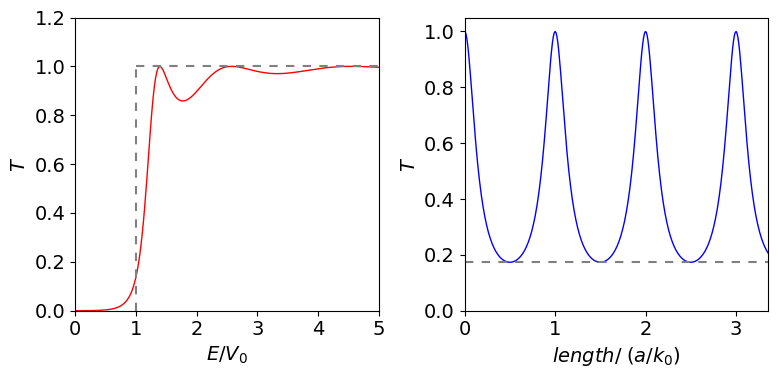

In [9]:
# define r as E/V0, m and hbar as 1 a as 5  problem 33 chapter 10

fig1= plt.figure( figsize=(8, 4) )
plt.rcParams.update({'font.size': 14})  # set font size for plots
ax0 = fig1.add_subplot(1,2,1)
ax1 = fig1.add_subplot(1,2,2)

a = 1
hbar = 1
T0 = lambda x :  1.0/(1.0 + (1/(4.0*x*(x-1)))* np.sin(5*np.sqrt(x-1))**2) 
T1 = lambda x :  1.0/(1.0 + (1/(4.0*x*(1-x)))*np.sinh(5*np.sqrt(1-x))**2) 
     
E0 = np.linspace(1+1e-3,5, 200)
E1 = np.linspace(1e-6,1-1e-3, 200)

ax0.plot(E0, T0(E0),color='red',linewidth=1)
ax0.plot(E1, T1(E1),color='red',linewidth=1)

ax0.plot([1,1],[0,1],color='grey',linewidth=1.5,dashes=[4,4])
ax0.plot([1,5],[1,1],color='grey',linewidth=1.5,dashes=[4,4])
ax0.set_xlim([0,5])
ax0.set_ylim([0,1.2])
ax0.set_ylabel(r'$T$')
ax0.set_xlabel(r'$E/V_0$')

#ax0.axvline(1+(1*np.pi/5)**2,color='grey', linewidth=0.5)
#ax0.axvline(1+(2*np.pi/5)**2,color='grey', linewidth=0.5)

r  = 1.05
k2 = 5*np.sqrt(r-1)
x  = np.linspace(0.01,10*k2,400)
T  = lambda x ,r:  1.0/(1.0 + (1/(4.0*r*(r-1)))* np.sin(x*k2)**2) 

ax1.plot(x/(np.pi/k2),T(x,r),color='blue',linewidth=1)
ax1.set_ylim([0,1.05])
ax1.set_xlim([0,3*k2])
ax1.set_ylabel(r'$T$')
ax1.set_xlabel(r'$length / \;(a/k_0)$')
ax1.axhline(1.0/(1.0 + (1/(4.0*r*(r-1)))),color='grey',linewidth=1.5,dashes=[4,4] )
fig1.tight_layout()

# plt.savefig('diffeqn-fig40.png')
plt.show()

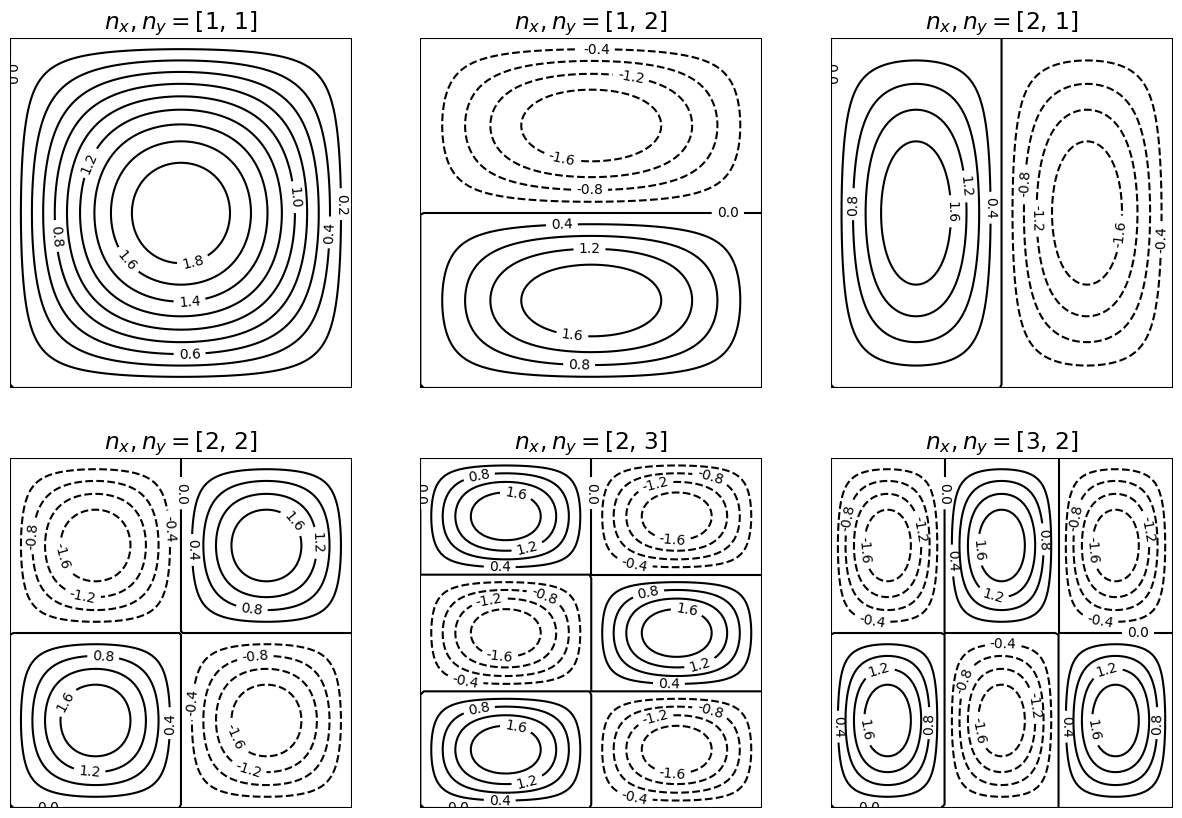

In [10]:
# 2 D box

fig = plt.figure(figsize=(15,10) )

cols = 3
tot  = 6
rows = tot//cols
rows = rows + tot % cols

phi = lambda x,y, nx,ny : np.sqrt(4.0/(a*b))*np.sin( nx*np.pi*x/a )* np.sin( ny*np.pi*y/b )

a = 1.0
b = 1.0
x = np.linspace(0,a,100)
y = np.linspace(0,b,100)
X, Y = np.meshgrid(x, y)

for j,i in enumerate([[1,1],[1,2],[2,1],[2,2],[2,3],[3,2]]):
    
    ax0 = fig.add_subplot(rows,cols,j+1)
    cp=plt.contour(X,Y,phi(X,Y,i[0],i[1]),10,colors='k')
    plt.clabel(cp, inline=True, fontsize=10,fmt='%2.1f')
    plt.title(r'$n_x, n_y = $'+str(i))
    plt.xlim([0,a])
    plt.ylim([0,b])
    plt.axis('Off')
    plt.plot([0,1],[0,0],color='black')
    plt.plot([0,0],[0,1],color='black')
    plt.plot([1,1],[0,1],color='black')
    plt.plot([1,0],[1,1],color='black')
    
plt.tight_layout
#plt.savefig('diffeqn-fig20.png')
plt.show()

TypeError: axis() got an unexpected keyword argument 'aspect'

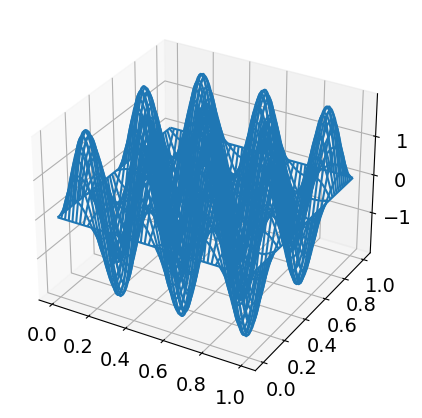

In [11]:
# 2 D box
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(6,5) )
ax = fig.add_subplot(111, projection='3d')

phi = lambda x,y, nx,ny : np.sqrt(4/(a*b))*np.sin( nx*np.pi*x/a )* np.sin( ny*np.pi*y/b )

a=1
b=1
x=np.linspace(0,a,100)
y=np.linspace(0,b,100)
X, Y = np.meshgrid(x, y)

ax.plot_wireframe(X,Y,phi(X,Y,6,4),rstride=2,cstride=2)
ax.axis(aspect='image')
ax.view_init(-105, -90)
plt.show()

In [8]:
f ,x =symbols('f x')

ans=dsolve(Eq(diff(f(x),x,x) + 9*f(x)- 1))
ans

0,1  [2.40482556]  3,1  [6.3801619] [6.3801619  9.76102313]


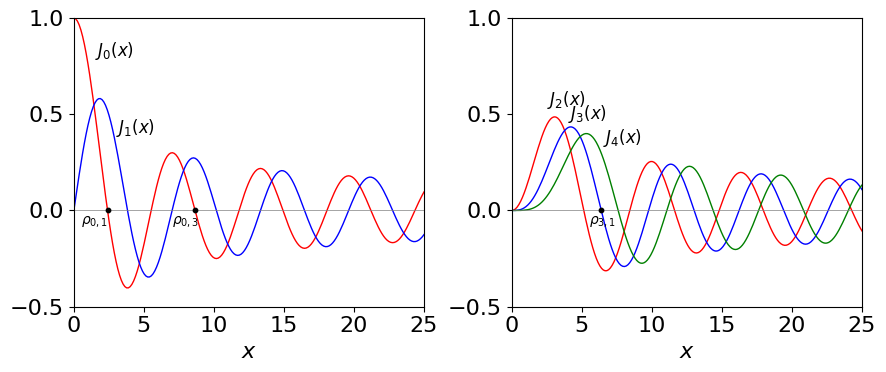

In [2]:
## particle on a disc Bessel equations


import scipy.special as sp
fig22 = plt.figure(figsize=(9,4) )

ax0 = fig22.add_subplot(1,2,1)
ax1 = fig22.add_subplot(1,2,2)

x = np.linspace(0,25,200)

q = 0
ax0.plot(x,sp.jv(q , x),color='red',linewidth=1)     # plot bessel J_n 
q = 1
ax0.plot(x,sp.jv(q , x),color='blue',linewidth=1)

ax0.set_ylim([-0.5,1])
ax0.set_xlim([0,25])
ax0.set_yticks([-0.5,0,0.5,1])

q = 2
ax1.plot(x,sp.jv(q , x),color = 'red',linewidth = 1)
q = 3
ax1.plot(x,sp.jv(q , x),color = 'blue',linewidth = 1)
q = 4
ax1.plot(x,sp.jv(q , x),color = 'green',linewidth = 1)

ax1.set_ylim([-0.5,1])
ax1.set_xlim([0,25])
ax1.set_yticks([-0.5,0,0.5,1])

ax0.axhline(0,color='grey',linewidth = 0.5 )
ax1.axhline(0,color='grey',linewidth = 0.5 )

ax0.text(1.5,0.8,r'$J_0(x)$',zorder=12,fontsize=12)
ax0.text(3,0.4,r'$J_1(x)$',zorder=12,fontsize=12)
ax0.text(7,-0.075,r'$\rho_{0,3}$',fontsize=10,zorder=12)
ax0.text(0.5,-0.075,r'$\rho_{0,1}$',fontsize=10,zorder=12)

ax1.text(2.5,0.55,r'$J_2(x)$',zorder=12,fontsize=12)
ax1.text(4, 0.475,r'$J_3(x)$',zorder=12,fontsize=12)
ax1.text(6.5,0.35,r'$J_4(x)$',zorder=12,fontsize=12)

ax1.text(5.5,-0.075,r'$\rho_{3,1}$',fontsize=10,zorder=12)

ax0.scatter([sp.jn_zeros(0,1)],[0],s=10,color = 'black', marker = 'o',zorder=12)  # zeros(q,n)  in J_n
ax1.scatter([sp.jn_zeros(3,1)],[0],s=10,color = 'black', marker = 'o',zorder=12)
ax0.scatter([sp.jn_zeros(0,3)[2]],[0],s=10,color = 'black', marker = 'o',zorder=12)

print('0,1 ',sp.jn_zeros(0,1),' 3,1 ',sp.jn_zeros(3,1), sp.jn_zeros(3,2))


ax0.set_xlabel(r'$x$')
ax1.set_xlabel(r'$x$')

plt.tight_layout()

#plt.savefig('diffeqn-fig21-leftpart.png')
plt.show()



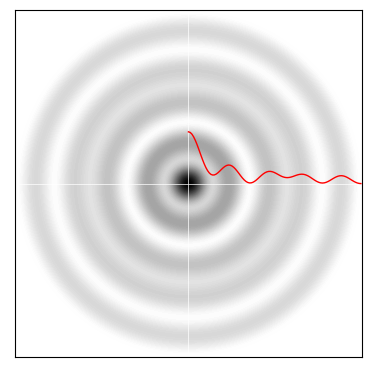

In [7]:
# As contour plot. 

fig220 = plt.figure(figsize=(4,4) )

r0 = lambda q,n: sp.jn_zeros(q,n)[n-1]

f01 = lambda q,n,x: sp.jv(q , x*r0(q,n)/rad)


q0, n0 = 0, 5
q1, n1 = 2, 4
q2, n2 = 7, 2

rad = 10

#print('r0',r0(q0,n0))

# Create the mesh in polar coordinates and compute corresponding Z.

r = np.linspace(0, rad, 100)
p = np.linspace(0, 2*np.pi, 150)

R, P = np.meshgrid(r, p)

# Express the mesh in the cartesian system.

X, Y = R*np.cos(P), R*np.sin(P)


Zq0 = f01(q0,n0, np.sqrt(X**2 + Y**2) )
Zq1 = f01(q1,n1, np.sqrt(X**2 + Y**2) )
Zq2 = f01(q2,n2, np.sqrt(X**2 + Y**2) )

plt.axis('equal')
#print(np.min(Z),np.max(Z))
plt.contourf(X, Y, (Zq0**2+Zq1**2+Zq2**2),levels=100,cmap='binary')  #, antialiased=False)

#plt.contourf(X, Y, (Zq0+Zq1+Zq2)**2,levels=100,cmap='binary')  #, antialiased=False)

plt.plot(r,3*( f01(q0,n0,r )**2 + f01(q1,n1,r )**2+ f01(q2,n2,r )**2 ),linewidth=1,color='red',zorder=10)

plt.axhline(0,color='white',linewidth=0.5)
plt.axvline(0,color='white',linewidth=0.5)

plt.xlim([-10,10])
plt.ylim([-10,10])
plt.xticks([])
plt.yticks([])

plt.tight_layout()

#plt.savefig('diffeqn-fig21c.png')
plt.show()

 n=   [1       2       3       4       5       6       7       8       9]
q= 0 [ 2.405  5.52   8.654 11.792 14.931]
q= 1 [ 3.832  7.016 10.173 13.324 16.471]
q= 2 [ 5.136  8.417 11.62  14.796 17.96 ]
q= 3 [ 6.38   9.761 13.015 16.223 19.409]
q= 4 [ 7.588 11.065 14.373 17.616 20.827]
q= 5 [ 8.771 12.339 15.7   18.98  22.218]
q= 6 [ 9.936 13.589 17.004 20.321 23.586]
q= 7 [11.086 14.821 18.288 21.642 24.935]
q= 8 [12.225 16.038 19.555 22.945 26.267]
q= 9 [13.354 17.241 20.807 24.234 27.584]
a0  6.044580444111271
sorted s  [2.405 3.832 5.136 5.52  6.38  7.016 7.588 8.417 8.654 8.771]


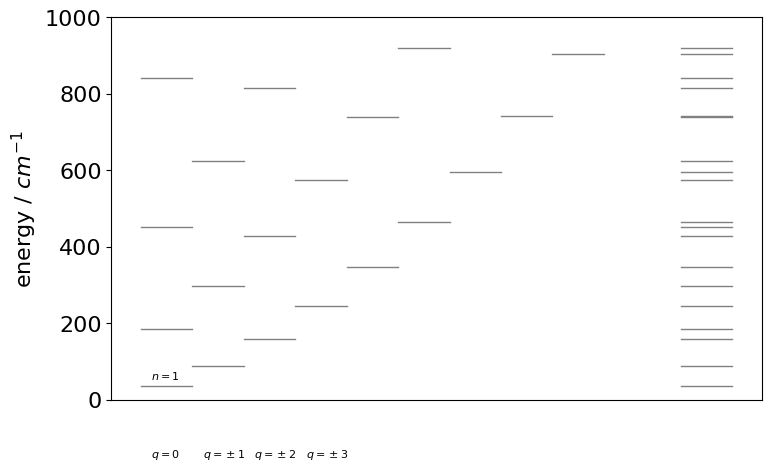

In [5]:
fig12 = plt.figure(figsize=(8,5) )
print(' n=  ',np.array2string(np.array([i for i in range(1,10,1)]),separator='       ' ) )
f0 = []

v1 = 10
v2 = 5

for q in range(v1):
    f0.extend(sp.jn_zeros(q,v2))
    print('q=',q, np.array2string( np.array(sp.jn_zeros(q,5) ),precision=3, separator=' ' )  )   
    
f1 = np.array(f0).reshape(v1,v2)
s = sorted(f0) 

hbar= 1.05457e-34 #js
m   = 9.10938e-31 #kg
a   = 7.13e-9      #m

a0 = hbar**2/(2*m)*(1/a**2) * 5.034e22  # to cm^-1
print('a0 ',a0)
print('sorted s ',np.array2string( np.array(s[0:10]),precision=3, separator=' ') )

#for i in range(10):
    #plt.plot([4,6],[ a0*s[i]**2,a0*s[i]**2],color='blue',linewidth=1)

for q in range(v1):
    for j in range(v2):      # j = n-1
        plt.plot( [q,q+1],[ a0*f1[q,j]**2, a0*f1[q,j]**2 ],color='grey', linewidth=1 )
        plt.plot( [v1+0.5,v1+1.5],[ a0*f1[q,j]**2, a0*f1[q,j]**2 ],color='grey', linewidth=1 )
        #print(q,j+1,a0*f1[q,j]**2/5.034e22)

plt.ylabel('energy / '+r'$cm^{-1}$') 
frame1 = plt.gca()
frame1.axes.get_xaxis().set_visible(False)

plt.ylim([0,1000])

plt.text(0.2,-150,r'$q=0$',fontsize=8)
plt.text(1.2,-150,r'$q=\pm 1$',fontsize=8)
plt.text(2.2,-150,r'$q=\pm 2$',fontsize=8)
plt.text(3.2,-150,r'$q=\pm 3$',fontsize=8)

plt.text(0.2,1.5*a0*f1[0,0]**2,r'$n=1$',fontsize=8)

#plt.annotate([0,1],xy={0.60,a0*s[0]**2+350},fontsize=12)
#plt.annotate([1,1],xy={0.60,a0*s[1]**2+350},fontsize=12)
#plt.annotate([2,1],xy={0.60,a0*s[2]**2+350},fontsize=12)
#plt.annotate([0,2],xy={0.60,a0*s[3]**2+350},fontsize=12)
#plt.annotate([3,1],xy={0.60,a0*s[4]**2+350},fontsize=12)
#plt.annotate([1,2],xy={0.60,a0*s[5]**2+350},fontsize=12)
plt.tight_layout()

#plt.savefig('diffeqn-fig21a.png')
plt.show()

### 

In [185]:
np.exp(-500/210)*100

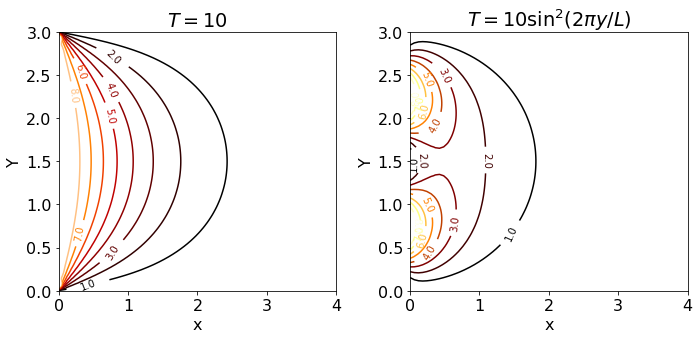

In [22]:
# diffusion
fig = plt.figure(figsize=(10,5) )

ax0 = fig.add_subplot(1,2,1)
ax1 = fig.add_subplot(1,2,2)

s = lambda y ,n : f(y)*np.sin(n*np.pi*y/L)

b = lambda n,y : (2/L) *quad(s, 0, L, args = n)[0]  # use [0] to return only answer nothing extra

V = lambda x, y,  nmax : sum([  b(n,y)*np.exp(-n*np.pi*x/L)*np.sin(n*np.pi*y/L) for n in range(1,nmax)] )

L = 3
f = lambda y:  10.0

x =   np.linspace(0,2*L, 100)
y =   np.linspace(0,  L, 100)
X,Y = np.meshgrid(x,y)

levels=[i for i in range(1,10)]
cp0=ax0.contour(X, Y, V(X,Y,40),levels=levels,cmap='gist_heat')
ax0.clabel(cp0, inline=True, fontsize=10,fmt='%2.1f')
ax0.set_ylabel('Y')
ax0.set_xlabel('x')
ax0.set_xlim([0,4])
ax0.set_title(r'$T=10$')

f = lambda y: 10*np.sin(2*np.pi*y/L)**2

levels=[i for i in range(1,13,1)]
cp1=ax1.contour(X, Y, V(X,Y,40),levels=levels,cmap='afmhot')
ax1.clabel(cp1, inline=True, fontsize=10,fmt='%2.1f')
ax1.set_ylabel('Y')
ax1.set_xlabel('x')
ax1.set_xlim([0,4])
ax1.set_title(r'$T=10\sin^2(2\pi y/L)$')

plt.tight_layout()
#plt.savefig('diffeqn-fig23.png')
plt.show()

0.009875870514112825


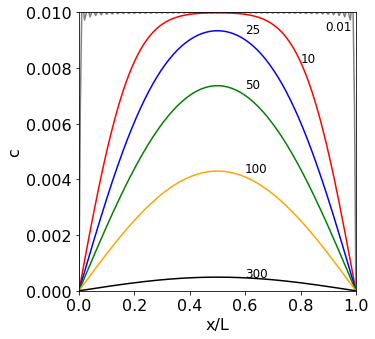

In [25]:
# eqn 55 56
fig = plt.figure(figsize=(5.5,5) )
s = lambda x,n : f(x)* np.sin(n*np.pi*x/L)

b = lambda n,x : (2/L)* quad(s, 0, L, args = n)[0]  # integrate use [0] to return only answer nothing extra

c = lambda x,t, nmax : sum([  b(n,x)*np.exp(-Dc*(n*np.pi/L)**2*t)*np.sin(n*np.pi*x/L) for n in range(1,nmax)] )

L = 10.0
Dc= 11.0e-2   #  diff coeff  lysozyme nm^2/ns

f = lambda x:  10.0e-3

print(c(0.5,0.10,40))

x =   np.linspace(0,  L, 200)
t =   np.linspace(0,  0.25e-3, 200)

cols=['grey','red','blue','green','orange','black']

for j,i in enumerate([0.01,10,25,50,100,300] ):
    plt.plot(x/L,c(x,i,100), color = cols[j])
    if j >1:
        plt.annotate(str(i),xy=(0.6,c(5.5,i,10)),fontsize=12 )
    if j <1:
        plt.annotate(str(i),xy=(0.89,c(4,i,10)),fontsize=12 )
    if j == 1:
        plt.annotate(str(i),xy=(0.8,c(8,i,10)),fontsize=12 )

plt.ylabel('c')
plt.xlabel('x/L')
plt.xlim([0,1])
plt.ylim([0,f(0)])

plt.tight_layout()
#plt.savefig('diffeqn-fig24.png')
plt.show()


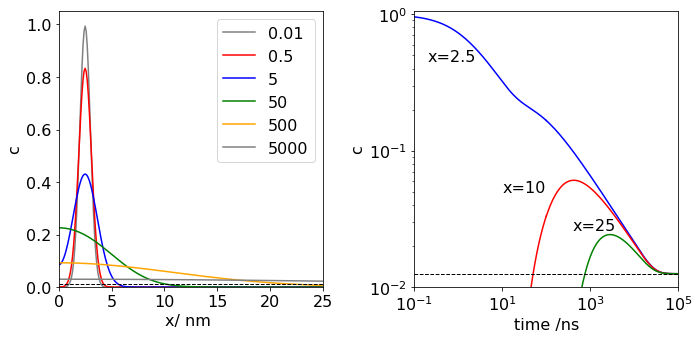

In [31]:
# difusion in closed tube 

fig = plt.figure(figsize=(10,5) )

ax0 = fig.add_subplot(1,2,1)
ax1 = fig.add_subplot(1,2,2)

s = lambda x,n : f(x)* np.cos(n*np.pi*x/L)

b = lambda n,x : (2.0/L)* quad(s, 0, L, args = n)[0]  # integrate use [0] to return only answer nothing extra

c = lambda x,t, nmax : b0/2.0 +  sum([ b(n,x)*np.exp(-Dc*t*(n*np.pi/L)**2)*np.cos(n*np.pi*x/L) for n in range(1,nmax)] )

f = lambda x:  np.exp(-2*(x-2.5)**2)

b0 = (2.0/L)* quad(f, 0, L)[0]     # 1/2 int(f(x)) to get average conc 

#print(b0,b(3,0.5))
L = 100.0
Dc= 11.0e-2   #  diff coeff  lysozyme nm^2/ns

#print(c(0.5,0.10,40))

x =   np.linspace(0,  L, 1000)

nn=200
cols=['grey','red','blue','green','orange','grey']

for j,i in enumerate([0.01,0.5,5,50,500,5000] ):
    ax0.plot(x,c(x,i,nn), color = cols[j],label=str(i))

#plt.plot(x/L,f(x),linestyle='dashed',color='red')
ax0.axhline(b0/2,color='black',linewidth=1,linestyle='dashed')
ax0.set_ylabel('c')
ax0.set_xlabel('x/ nm ')

ax0.set_xlim([0,25])
ax0.set_ylim([0.0,1.05])
ax0.legend()


ta = np.linspace(0.1,  100, 5000)
tb = np.linspace(100,  1e5, 5000)

ax1.plot(ta,c(2.5,ta,nn),color='blue')
ax1.plot(ta,c(10,ta,nn),color='red')
ax1.plot(ta,c(25,ta,nn),color='green')
ax1.plot(tb,c(2.5,tb,nn),color='blue')
ax1.plot(tb,c(10,tb,nn),color='red')
ax1.plot(tb,c(25,tb,nn),color='green')

ax1.axhline(b0/2,color='black',linewidth=1,linestyle='dashed')
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylim([0.01,1.05])
ax1.set_xlim([0.1,1e5])
ax1.set_xlabel( 'time /ns')
ax1.set_ylabel('c')
ax1.annotate('x=2.5',xy=(0.2,0.45))
ax1.annotate('x=10',xy=(10,0.05))
ax1.annotate('x=25',xy=(400,0.026))

plt.tight_layout()
#plt.savefig('diffeqn-fig25a.png')
plt.show()

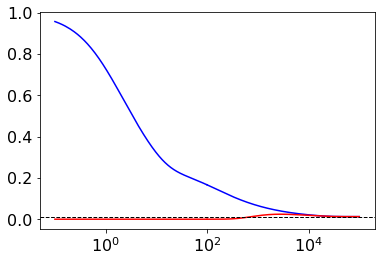

In [32]:
ta =   np.linspace(0.1,  100, 5000)
tb=np.linspace(100,  1e5, 5000)

plt.plot(ta,c(2.5,ta,nn),color='blue')
plt.plot(ta,c(25,ta,nn),color='red')
plt.plot(tb,c(2.5,tb,nn),color='blue')
plt.plot(tb,c(25,tb,nn),color='red')
plt.axhline(b0/2,color='black',linewidth=1,linestyle='dashed')
plt.xscale('log')
plt.show()

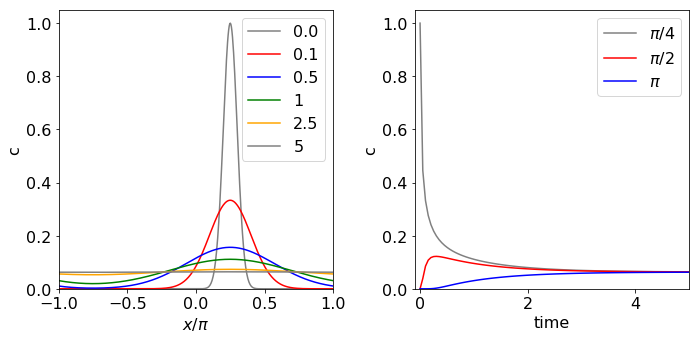

In [34]:
# on loop
fig = plt.figure(figsize=(10,5) )

ax0 = fig.add_subplot(1,2,1)
ax1 = fig.add_subplot(1,2,2)

sa = lambda x,n : f(x)* np.sin(n*np.pi*x/L)

a = lambda n,x : (1.0/L)* quad(sa, -np.pi, np.pi, args = n)[0]

sb = lambda x,n : f(x)* np.cos(n*np.pi*x/L)
b = lambda n,x : (1.0/L)* quad(sb, 0, L, args = n)[0]  # integrate use [0] to return only answer nothing extra

c = lambda x,t, nmax : b0/2.0 + sum([ np.exp(-Dc*t*(n*np.pi/L)**2)*(a(n,x)*np.sin(n*np.pi*x/L)+b(n,x)*np.cos(n*np.pi*x/L)) for n in range(1,nmax)] )

f = lambda x:  np.exp(-20.0*(x-np.pi/4.0)**2)

b0 = (1/np.pi)* quad(f, -np.pi,np.pi)[0]     # 1/2 int(f(x)) to get average conc 

#print(b0,b(3,0.5))
L = np.pi
Dc= 1 # 11.0e-2   #  diff coeff  lysozyme nm^2/ns

#print(c(0.5,0.10,40))

x =   np.linspace(-L,  L, 500)

nn=50
cols=['grey','red','blue','green','orange','grey']

for j,i in enumerate([0.00,0.1,0.5,1,2.5,5] ):
    ax0.plot(x/np.pi,c(x,i,nn), color = cols[j],label=str(i))

ax0.set_ylabel('c')
ax0.set_xlabel(r'$x/\pi$')

ax0.set_xlim([-1,1])
ax0.set_ylim([0.0,1.05])
ax0.legend()

t=np.linspace(0,5,100)

kk=['/4','/2','']

for j,i in enumerate([np.pi/4,np.pi/2,np.pi] ):
    ax1.plot(t,c(i,t,nn), color = cols[j],label=r'$\pi $'+kk[j]  )

ax1.set_ylabel('c')
ax1.set_xlabel('time')

ax1.set_xlim([-0.1,5])
ax1.set_ylim([0.0,1.05])
ax1.legend()
plt.tight_layout()
#plt.savefig('diffeqn-fig26a.png')
plt.show()

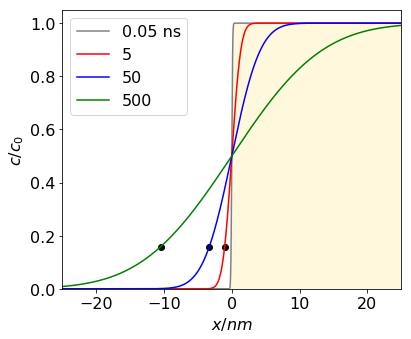

In [36]:
from scipy.special import erfc

fig = plt.figure(figsize=(6,5) )

c = lambda x,t: (c0/2)*erfc( -x/np.sqrt(4*Dc*t))

Dc =  11e-2  # nm^2/ns
c0 = 1.0
x=np.linspace(-25,25,1000)

cols=['grey','red','blue','green','orange','grey']
plt.fill_between(x,c(x,0.01),color='cornsilk')
#for j,i in enumerate([0.1,5,50,500] ):
for j,i in enumerate([0.05,5,50,500] ):
    if j==0:
        plt.plot(x,c(x,i),color=cols[j],label = str(i)+' ns')
    else:
        plt.plot(x,c(x,i),color=cols[j],label = str(i))
        xbar = np.sqrt(2*Dc*i)
        plt.scatter([-xbar],[c(-xbar,i)],color ='black')

plt.xlabel(r'$x / nm$')
plt.ylabel(r'$c / c_0$')
plt.ylim([0,1.05])
plt.xlim([-25,25])

plt.legend()
plt.tight_layout()
#plt.savefig('diffeqn-fig27.png')
plt.show()


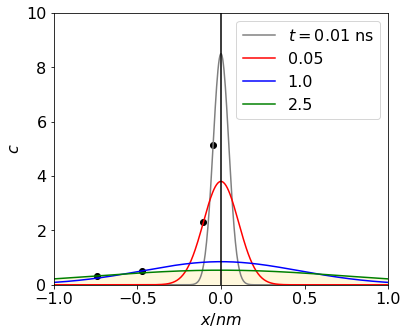

In [38]:

fig = plt.figure(figsize=(6,5) )


cdelta=lambda x,t: (1.0/np.sqrt(4*np.pi*Dc*t))*np.exp(-x**2/(4*Dc*t))

Dc =  11e-2  # nm^2/ns
c0 = 1.0
x=np.linspace(-1,1,500)


cols=['grey','red','blue','green','orange','grey']
plt.fill_between(x,cdelta(x,2.5),color='cornsilk')
for j,i in enumerate([0.01,0.05,1.0,2.5] ):
    if j==0:
        plt.plot(x,cdelta(x,i),color=cols[j],label = r'$t =$'+str(i)+' ns')
    else:
        plt.plot(x,cdelta(x,i),color=cols[j],label = str(i))
    xbar=np.sqrt(2*Dc*i)
    plt.scatter([-xbar],[cdelta(-xbar,i)],color ='black')
plt.axvline(0,color='black')
plt.ylim([0,10])
plt.xlim([-1,1])
plt.ylabel(r'$c$')
plt.xlabel(r'$x /nm$')
plt.legend()
plt.show()

1.0


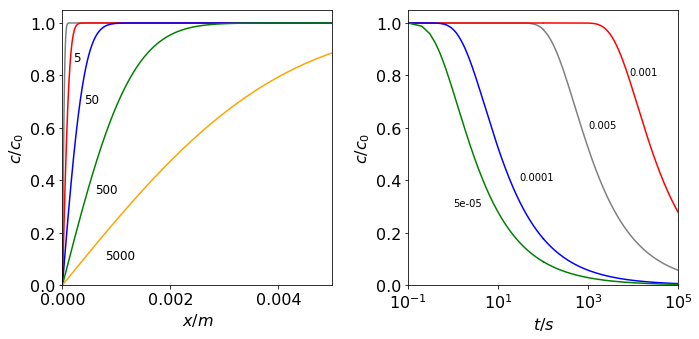

In [2]:
import scipy.special as sp

fig = plt.figure(figsize=(10,5) )
plt.rcParams.update({'font.size': 16})  # set font size for plots

ax0 = fig.add_subplot(1,2,1)
ax1 = fig.add_subplot(1,2,2)


c= lambda x, t: c0*sp.erf( x/np.sqrt(4*Dc*t))

Dc=1e-9
c0=1
print( c(0.003,5) )

x = np.linspace(0,5e-3,500)
cols=['grey','red','blue','green','orange','grey']
for j,i in enumerate([0.5,5,50,500,5000]):
    ax0.plot( x, c(x,i),color=cols[j] )
    ax0.annotate(str(i),xy=(2e-4*j,c(2e-4*j,i)-0.1),fontsize=12 )
ax0.set_ylim([0,1.05])
ax0.set_xlim([0,5e-3])
ax0.set_ylabel(r'$c/c_0$')
ax0.set_xlabel(r'$x /m$')
ax0.set_xticks([0,0.002,0.004] )

ta = np.linspace(0.1,1e2,1000)
tb = np.linspace(1e2,1e5,4000)

cols=['grey','red','blue','green','orange','grey']
for j,i in enumerate([0.001,0.005,0.0001,0.00005]):
    ax1.plot( ta, c(i,ta),color=cols[j] )
    ax1.plot( tb, c(i,tb),color=cols[j] )

ax1.annotate(str(0.001),xy=(8000,0.8),fontsize=10 )
ax1.annotate(str(0.005),xy=(1000,0.6),fontsize=10 )
ax1.annotate(str(0.0001),xy=(30,0.4),fontsize=10 )
ax1.annotate(str(0.00005),xy=(1,0.3),fontsize=10 )
ax1.set_xscale('log')
ax1.set_ylim([0,1.05])
ax1.set_xlim([0.1,1e5])
ax1.set_ylabel(r'$c/c_0$')
ax1.set_xlabel(r'$t /s$')

plt.tight_layout()

#plt.savefig('diffeqn-fig28.png')
plt.show()


1.0


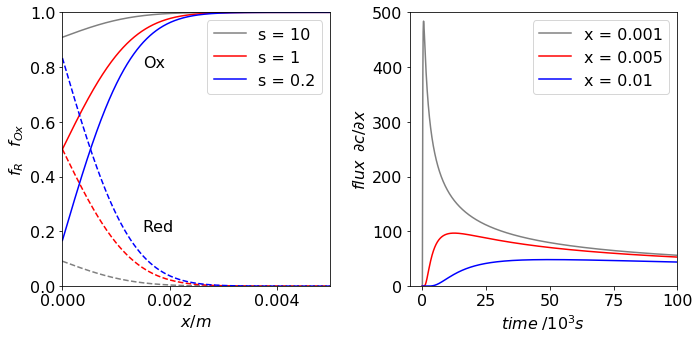

In [34]:
#fig 29
fig = plt.figure(figsize=(10,5) )
plt.rcParams.update({'font.size': 16})  # set font size for plots
ax0 = fig.add_subplot(1,2,1)
ax1 = fig.add_subplot(1,2,2)

c = lambda x, t: c0*sp.erf( x/np.sqrt(4*Dc*t))

dcdx = lambda x,t: (c0/np.sqrt(np.pi*Dc*t))*np.exp(-x**2/(4*Dc*t))

Dc = 1e-9
c0 = 1
print( c(0.003,5) )

x = np.linspace(0,5e-3,500)

cols=['grey','red','blue','green','orange','grey']
for j,s in enumerate([10,1,1/5]):
    ax0.plot(x,(1-c(x,500))/(1+s),color=cols[j],linestyle='dashed')
    ax0.plot(x,(s+c(x,500))/(1+s),color=cols[j],label='s = '+str(s))

ax0.annotate('Ox',xy=[0.0015,0.8])
ax0.annotate('Red',xy=[0.0015,0.2])
ax0.set_ylim([0,1])
ax0.set_xlim([0,5e-3])
ax0.set_ylabel(r'$f_{R}\quad f_{Ox}$')
ax0.set_xlabel(r'$x/m$')
ax0.set_xticks([0,0.002,0.004] )
ax0.legend()

dcdx=lambda x,t: (c0/np.sqrt(np.pi*Dc*t))*np.exp(-x**2/(4*Dc*t))

tmax = 1e5
t = np.linspace(0.1,tmax,5000)
cols=['grey','red','blue','green','orange','grey']
for j,i in enumerate([0.001,0.005,0.01]):
    ax1.plot( t/1e3, dcdx(i,t),color=cols[j],label='x = '+str(i) )


ax1.set_ylim([0,500])

ax1.set_xlim([-0.05*tmax/1e3,tmax/1e3])
ax1.set_ylabel(r'$flux\;\; \partial c/\partial x$')
ax1.set_xlabel(r'$time \;/10^3 s$')

ax1.legend()
#ax1.ticklabel_format(axis='x', style='sci', scilimits=(0,4))
#ax1.ticklabel_format(useOffset=False)
plt.tight_layout()
#plt.savefig('diffeqn-fig29.png')
plt.show()

In [ ]:
# int int exp(-Dt*k**2-I*k*(s-x))- exp(-Dt*k**2+I*k*(s+x)) k=-inf,inf, s=0,inf
# sympy fail to do this , is OK in Maple


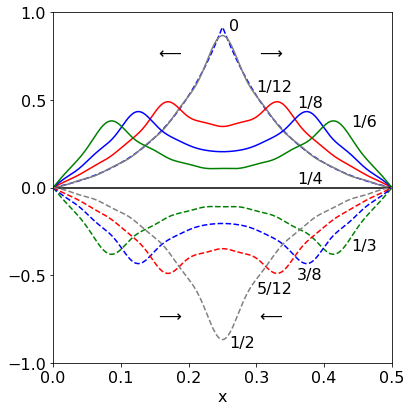

In [48]:
# standing wave
fig = plt.figure(figsize=(6,6) )
f  = lambda x: np.exp(-abs(2*x-L)*5) - np.exp(-L*5)  # initial function of plucked string

f01= lambda x,n : f(x)*np.sin(n*np.pi*x/L)

b  = lambda n : (2/L)*quad( f01,0,L,args=n )[0]  # get just answer not error as well

u  = lambda x,t, maxn : sum( [  b(n)*np.cos(n*np.pi*c*t/L)*np.sin(n*np.pi*x/L) for n in range(1,nmax) ] )

L =   0.5
c =   100.0
T =   2.0*L/c
nmax= 20
t   = T/12.0

x=np.linspace(0,L,500)

#plt.plot(x,u(x,t,nmax))
plt.plot(x,f(x),color='blue',linestyle='dashed')
alist=['0', '1/12', '1/8', '1/6', '1/4', '1/3', '3/8', '5/12', '1/2']
cols=['grey','red','blue','green','black','green','blue','red','grey']
for j,i in enumerate(alist):
    k=0
    if j !=0:
        num,den =i.split('/')
        k=float(num)/float(den)
    ls='solid'
    if j>4: ls='dashed'
    plt.plot( x, u(x,k*T,nmax),color=cols[j],linestyle=ls )
    
plt.xlabel('x')
plt.ylim([-1,1])
plt.xlim([0,L])
plt.yticks([-1,-0.5,0,0.5,1])
plt.annotate(r'$\longrightarrow$',xy=(0.3,0.75))
plt.annotate(r'$\longleftarrow$',xy=(0.15,0.75))
plt.annotate(r'$\longrightarrow$',xy=(0.15,-0.75))
plt.annotate(r'$\longleftarrow$',xy=(0.3,-0.75))
plt.annotate(alist[0],xy=(0.26,0.9))
plt.annotate(alist[1],xy=(0.3,0.55))
plt.annotate(alist[2],xy=(0.36,0.46))
plt.annotate(alist[3],xy=(0.44,0.35))
plt.annotate(alist[5],xy=(0.44,-0.36))
plt.annotate(alist[6],xy=(0.36,-0.52))
plt.annotate(alist[7],xy=(0.30,-0.6))
plt.annotate(alist[8],xy=(0.26,-0.91))
plt.annotate(alist[4],xy=(0.36,0.025))

plt.tight_layout()

#plt.savefig('diffeqn-fig30.png')
plt.show()

In [23]:
f = 1
for i in range(10):
    f = f*(i + 1)
print(f)

3628800


In [24]:
s='0/'
num,den=s.split('/')
print(num,den)

0 


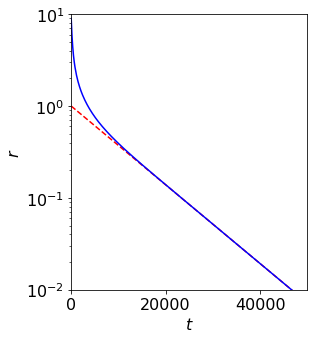

In [10]:
fig = plt.figure(figsize=(5,5) )
plt.rcParams.update({'font.size': 16})  # set font size for plots
t = np.linspace(0,0.8e5,500)
D = 1e-9
L = 0.01

r= lambda t,m: sum([np.exp(-n**2*D*t*(np.pi/L)**2) for n in range(1,m)])


plt.plot(t,r(t,2),linestyle='dashed',color='red')

plt.plot(t,r(t,10),color='blue')
plt.yscale('log')
plt.ylim([1e-2,1e1])
plt.xlim([0,0.5e5])
plt.xlabel(r'$t$')
plt.ylabel(r'$r$')
#plt.ticklabel_format(axis='x', style='sci', scilimits=(0,3))
plt.tight_layout()
#plt.savefig('diffeqn-fig40a.png')
plt.show()

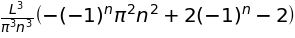

In [26]:
a,x,L=symbols('a x L')
n = symbols('n', integer=True)

ans=integrate(x**2*sin(n*pi*x/L),(x,0,L),conds='none' )
simplify(ans)

In [27]:
ans1=diff(sech(a*x)**2,x)
ans1

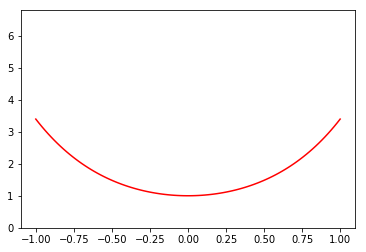

In [61]:
# Q16 k==k_0e^{-E_0/RT}\cosh\left(\frac{V}{2RT}  \right)$$

k0=1
E0=1
R=8.314
T=3000

k = lambda V,T : k0*np.exp(-E0/(R*T))*np.cosh(V*94.4e3/(2*R*T))


V = np.linspace(-1,1,100)


plt.plot( V, k(V,T) ,color='red')
plt.ylim([0,2*k(V[0],T)])

plt.show()

$$\displaystyle c(x,y,t)=\frac{1}{2\pi}\int_{-\infty}^\infty e^{-Dk_x^2t}e^{ik_xx}dk_x\int_{-\infty}^\infty e^{-Dk_y^2t}e^{ik_yx}dk_y=\frac{1}{4\pi Dt}e^{-(x^2+y^2)/(4Dt)}$$

0.0 0.07957747154594767


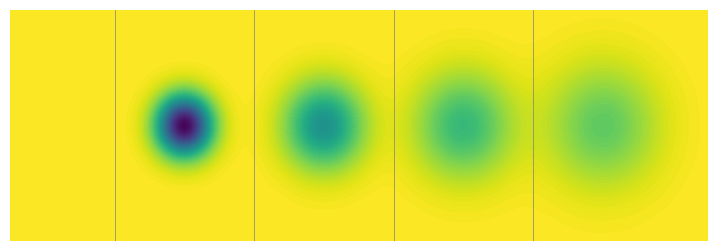

In [6]:
# 2D diffusion section 18.6


from matplotlib import cm

D = 0.15

t = [1,2,3,4,5,6,7,8,9,10]

x = np.linspace(-15,15,201)
y = np.linspace(-3,3,201)

c = lambda x,x0,y,y0,t: 1/(4*np.pi*t)*np.exp(-((x-x0)**2 + (y+y0)**2)/(4*D*t))


#fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
fig = plt.figure(figsize=(9,3))
#ax = fig.add_subplot(projection='3d')
X, Y = np.meshgrid(x,y)
#R = np.sqrt(X**2 + Y**2)
x0 = 0
y0 = 0


Z0 = c(x[100],x0,y[100],y0,t[0])
Z = c(X,x0,Y,y0,t[0])/Z0
# Plot the surface.
#plt.contourf(X, Y, Z, cmap=cm.coolwarm)  #, antialiased=False)
print(x[100],Z0)
x0 = 4
y0 = 0
Z2 = c(X,x0,Y,y0,t[1])/Z0
x0 = 8
Z3 = c(X,x0,Y,y0,t[2])/Z0
x0 = 12
Z4 = c(X,x0,Y,y0,t[3])/Z0

plt.contourf(X, Y, Z+Z2+Z3+Z4, levels=100,cmap=cm.viridis_r)  #, antialiased=False)
#plt.contour(X, Y, Z+Z2+Z3+Z4, levels=[0.15,0.5],linewidths=1,colors=['white','red'])  #, antialiased=False)

plt.axis('off')
plt.xlim([-5,15])
plt.ylim([-3,3])
plt.axvline(2,linewidth=0.5, color='gray')
plt.axvline(-2,linewidth=0.5, color='gray')
plt.axvline(6,linewidth=0.5, color='gray')
plt.axvline(10,linewidth=0.5, color='gray')
#plt.xticks([])
#plt.yticks([])
plt.show()

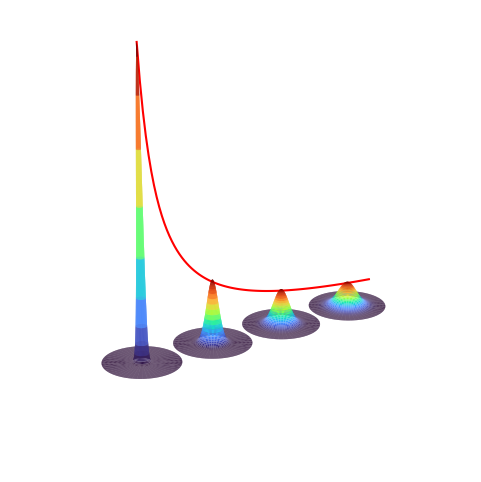

In [67]:
# in polar coords
# %matplotlib notebook
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')

cr = lambda r,t: 1/(4*np.pi*D*t)*np.exp(-(r**2)/(4*D*t))

# Create the mesh in polar coordinates and compute corresponding Z.
r = np.linspace(0, 8, 100)
p = np.linspace(0, 2*np.pi, 150)
R, P = np.meshgrid(r, p)


# Express the mesh in the cartesian system.
X, Y = R*np.cos(P), R*np.sin(P)

D = 0.15
t = np.linspace(1,20,11)
x = np.linspace(0,40,100)
y = np.linspace(0,40,100)
tt = np.linspace(1e-3,1/70,100)  # max time 8 
#tt = np.linspace(1e-3,20,100)  # max time 8 

# Plot the surface.
xyd=[0,12,24,36]

for i in range(4):
    Z = cr(R,t[i*2])
    ax.plot_surface(X+xyd[i], Y+xyd[i], Z/cr(0,t[0]),
                    cmap= cm.turbo,rcount=50,ccount=50,linewidth=0)

#for i in range(100):
#    ax.scatter(x[i],y[i],c(0,0,0,0,tt[i])/c(0,0,0,0,1e-3),s=1,color='red')
    
ax.plot(x,y,c(0,0,0,0,tt)/c(0,0,0,0,1e-3),color='red',linewidth=1.5)

    
ax.set_zlim([0,0.65])
ax.axis('off')
ax.view_init(21, -80, 0)
#plt.savefig('diffeqn-fig30g.png')

plt.show()


In [17]:
t

array([ 1.  ,  1.95,  2.9 ,  3.85,  4.8 ,  5.75,  6.7 ,  7.65,  8.6 ,
        9.55, 10.5 , 11.45, 12.4 , 13.35, 14.3 , 15.25, 16.2 , 17.15,
       18.1 , 19.05, 20.  ])

$$\displaystyle \frac{x}{a_0-x}+\ln\left(\frac{a_0-x}{a_0}\right)=\frac{t}{2k_3K_e}$$

In [33]:
a0,x,t=symbols('a0,x,t')
f01=x/(a0-x)**2
( integrate(f01,(x,0,x)) )

In [34]:
z,a,t=symbols('z,a,t')

f01=z/(1-z)+ln((1-z))
f01

In [35]:
f01.series()

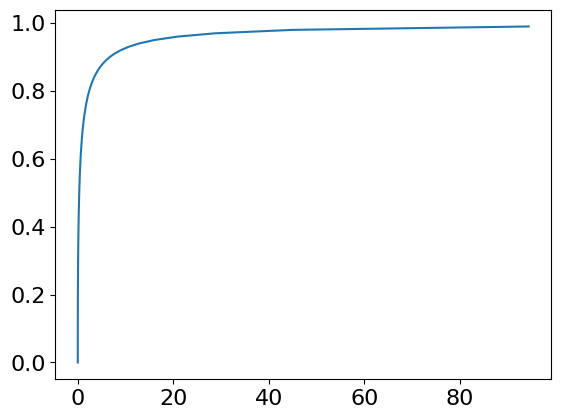

In [71]:
#. 10- 2.2  BH3CO

a = 1
f01=lambda z:a*( z/(1-z)+np.log(1-z))
n=100
y=np.zeros(n,dtype=float)
t=np.zeros(n,dtype=float)
for i in range(0,n):
    t[i]= f01(i/n)
    y[i]= i/n
plt.plot(t,y) 
plt.show()